# Smart Traffic Accident Risk Analysis & Visualization
**Notebook:** end-to-end walk-through - raw data -> cleaning -> EDA -> insights.

| Step | What happens | Script that does the same job |
|---|---|---|
| 1 | Load & inspect the raw data | `python/generate_dataset.py` (creates the raw file) |
| 2 | Clean the data with Pandas | `python/data_cleaning.py` |
| 3 | Exploratory Data Analysis | `python/exploratory_analysis.py` |
| 4 | SQL analysis in MySQL | `sql/accident_analysis.sql` |
| 5 | Dashboard | Power BI - see `powerbi/dashboard_documentation.md` |

> Run all cells from top to bottom (`Kernel -> Restart & Run All`). The notebook must stay inside the `notebooks/` folder.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent                      # project root (notebook lives in notebooks/)
sys.path.append(str(ROOT / "python"))
from data_cleaning import clean_dataframe     # re-use the exact cleaning code from the script

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
SEV = ["Minor", "Serious", "Fatal"]
SEV_COL = {"Minor": "#2E9E6B", "Serious": "#F2A33A", "Fatal": "#C8372D"}
print("Project root:", ROOT)

Project root: /home/claude/Smart-Traffic-Accident-Analysis


## 1. Load and inspect the RAW data

In [2]:
raw = pd.read_csv(ROOT / "data" / "raw" / "raw_accidents.csv")
print("Shape:", raw.shape)
raw.head()

Shape: (12160, 22)


,Accident_ID,Date,Time,Day_of_Week,Month,Year,Location,City,State,Weather_Condition,Road_Condition,Road_Type,Vehicle_Type,Number_of_Vehicles,Number_of_Casualties,Number_of_Fatalities,Accident_Severity,Speed_Limit,Light_Condition,Alcohol_Involved,Driver_Age,Driver_Gender
0,ACC-000001,2019-01-01,05:36,Tuesday,January,2019,OMR Sholinganallur,Chennai,Tamil Nadu,Cloudy,Under Construction,Urban Road,Two-Wheeler,1,1,0,Minor,50.0,Dawn/Dusk,No,55.0,Male
1,ACC-000002,2019-01-01,10:47,Tuesday,January,2019,Anna Salai Junction,Chennai,Tamil Nadu,Clear,Dry,Urban Road,Car,3,1,0,Minor,30.0,Daylight,No,53.0,Male
2,ACC-000003,2019-01-01,14:14,Tuesday,January,2019,NH44 Singhu Border,Delhi,Delhi,Clear,Dry,Highway,Car,2,1,1,Fatal,70.0,Daylight,No,48.0,Female
3,ACC-000004,2019-01-01,15:34,Tuesday,January,2019,Ring Road Ashram,Delhi,Delhi,Clear,Dry,Urban Road,Two-Wheeler,2,1,0,Minor,30.0,Daylight,No,31.0,Male
4,ACC-000005,2019-01-01,19:21,Tuesday,January,2019,VIP Road Airport,Kolkata,West Bengal,Clear,Dry,Urban Road,Car,1,3,0,Minor,40.0,Dawn/Dusk,NaN,59.0,Male


In [3]:
print("Duplicate rows:", raw.duplicated().sum())
print("\nMissing values:")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nDistinct spellings in City:", raw["City"].nunique(), "| Vehicle_Type:", raw["Vehicle_Type"].nunique())
print("Invalid ages (<18 or >80):", ((raw["Driver_Age"] < 18) | (raw["Driver_Age"] > 80)).sum())
print("Fatalities > Casualties:", (raw["Number_of_Fatalities"] > raw["Number_of_Casualties"]).sum())

Duplicate rows: 160

Missing values:
Weather_Condition    223
Road_Condition       202
Speed_Limit          107
Light_Condition      120
Alcohol_Involved     247
Driver_Age           329
Driver_Gender        233
dtype: int64

Distinct spellings in City: 40 | Vehicle_Type: 28
Invalid ages (<18 or >80): 47
Fatalities > Casualties: 26


## 2. Clean the data
The function `clean_dataframe()` (from `python/data_cleaning.py`) applies every cleaning rule. Each rule and its reason is documented
in that file (look for the `DECISION:` comments). Its log is hidden here to keep the notebook short - see `data/cleaned/cleaning_report.txt`.

In [4]:
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    df = clean_dataframe(raw)
print(f"Rows: {len(raw):,} -> {len(df):,}   |   Columns: {raw.shape[1]} -> {df.shape[1]}   |   Missing values left: {df.isna().sum().sum()}")
df.head()

Rows: 12,160 -> 12,000   |   Columns: 22 -> 33   |   Missing values left: 0


,Accident_ID,Date,Time,Hour,Day,Day_of_Week,Month_Num,Month,Year,Weekend_Flag,Day_Type,Time_Period,Location,City,State,Weather_Condition,Road_Condition,Road_Type,Vehicle_Type,Number_of_Vehicles,Number_of_Casualties,Number_of_Fatalities,Accident_Severity,Speed_Limit,Light_Condition,Alcohol_Involved,Driver_Age,Age_Group,Driver_Gender,Casualty_Rate,Fatality_Rate,Risk_Category,Mass_Casualty_Flag
0,ACC-000001,2019-01-01,05:36:00,5,1,Tuesday,1,January,2019,0,Weekday,Early Morning (5-7 AM),OMR Sholinganallur,Chennai,Tamil Nadu,Cloudy,Under Construction,Urban Road,Two-Wheeler,1,1,0,Minor,50,Dawn/Dusk,No,55,50-64,Male,1.00,0.0,Low,0
1,ACC-000002,2019-01-01,10:47:00,10,1,Tuesday,1,January,2019,0,Weekday,Morning Peak (8-10 AM),Anna Salai Junction,Chennai,Tamil Nadu,Clear,Dry,Urban Road,Car,3,1,0,Minor,30,Daylight,No,53,50-64,Male,0.33,0.0,Low,0
2,ACC-000003,2019-01-01,14:14:00,14,1,Tuesday,1,January,2019,0,Weekday,Midday (11 AM-3 PM),NH44 Singhu Border,Delhi,Delhi,Clear,Dry,Highway,Car,2,1,1,Fatal,70,Daylight,No,48,35-49,Female,0.50,100.0,High,0
3,ACC-000004,2019-01-01,15:34:00,15,1,Tuesday,1,January,2019,0,Weekday,Midday (11 AM-3 PM),Ring Road Ashram,Delhi,Delhi,Clear,Dry,Urban Road,Two-Wheeler,2,1,0,Minor,30,Daylight,No,31,25-34,Male,0.50,0.0,Low,0
4,ACC-000005,2019-01-01,19:21:00,19,1,Tuesday,1,January,2019,0,Weekday,Evening Peak (4-8 PM),VIP Road Airport,Kolkata,West Bengal,Clear,Dry,Urban Road,Car,1,3,0,Minor,40,Dawn/Dusk,Unknown,59,50-64,Male,3.00,0.0,Low,0


In [5]:
# Before / after for the messy text columns
pd.DataFrame({"unique values BEFORE": raw[["City","Weather_Condition","Vehicle_Type","Accident_Severity","Alcohol_Involved"]].nunique(),
              "unique values AFTER":  df[["City","Weather_Condition","Vehicle_Type","Accident_Severity","Alcohol_Involved"]].nunique()})

,unique values BEFORE,unique values AFTER
City,40,10
Weather_Condition,19,6
Vehicle_Type,28,7
Accident_Severity,12,3
Alcohol_Involved,8,3


## 3. Exploratory Data Analysis

### 3.1 Overview KPIs

In [6]:
kpi = pd.Series({
    "Total accidents": len(df),
    "Total casualties": df["Number_of_Casualties"].sum(),
    "Total fatalities": df["Number_of_Fatalities"].sum(),
    "Fatality rate (deaths per 100 casualties)": round(df["Number_of_Fatalities"].sum() / df["Number_of_Casualties"].sum() * 100, 2),
    "Avg casualties per accident": round(df["Number_of_Casualties"].mean(), 2)})
kpi.to_frame("value")

,value
Total accidents,12000.00
Total casualties,19839.00
Total fatalities,1634.00
Fatality rate (deaths per 100 casualties),8.24
Avg casualties per accident,1.65


### 3.2 Time patterns - year, month, weekday, hour

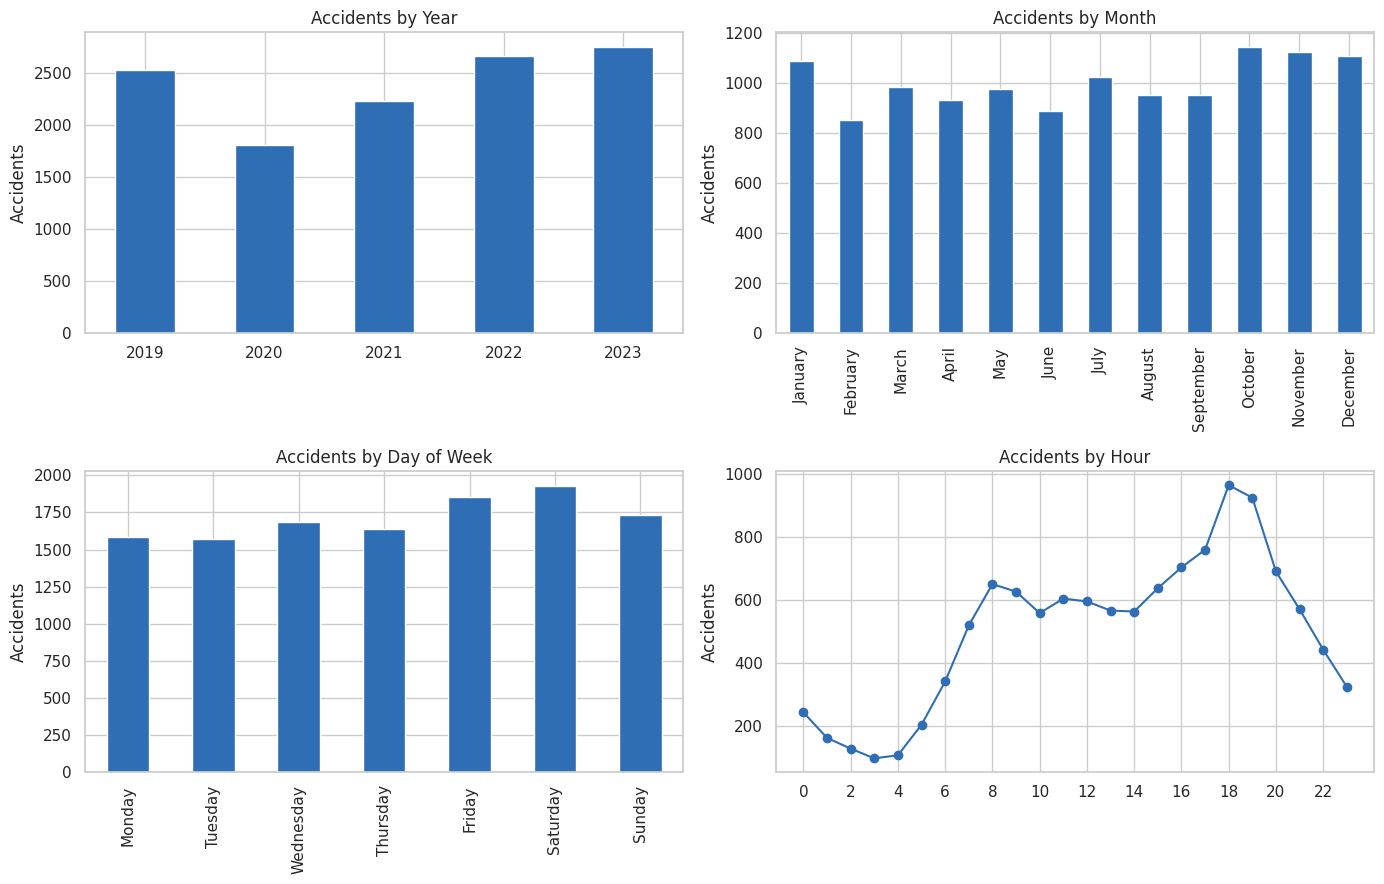

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
df.groupby("Year").size().plot(kind="bar", ax=ax[0,0], color="#2F6DB5", rot=0, title="Accidents by Year")
months = ["January","February","March","April","May","June","July","August","September","October","November","December"]
df["Month"].value_counts().reindex(months).plot(kind="bar", ax=ax[0,1], color="#2F6DB5", title="Accidents by Month")
days = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
df["Day_of_Week"].value_counts().reindex(days).plot(kind="bar", ax=ax[1,0], color="#2F6DB5", title="Accidents by Day of Week")
df.groupby("Hour").size().plot(ax=ax[1,1], marker="o", color="#2F6DB5", title="Accidents by Hour"); ax[1,1].set_xticks(range(0,24,2))
for a in ax.ravel(): a.set_xlabel(""); a.set_ylabel("Accidents")
plt.tight_layout(); plt.show()

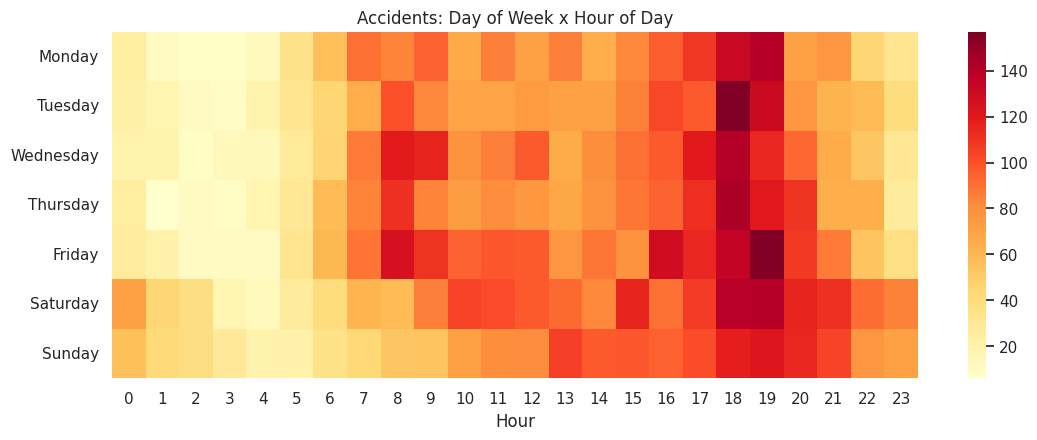

In [8]:
plt.figure(figsize=(13, 4.5))
sns.heatmap(df.pivot_table(index="Day_of_Week", columns="Hour", values="Accident_ID", aggfunc="count").reindex(days), cmap="YlOrRd")
plt.title("Accidents: Day of Week x Hour of Day"); plt.ylabel(""); plt.show()

### 3.3 Conditions - weather, road, vehicle

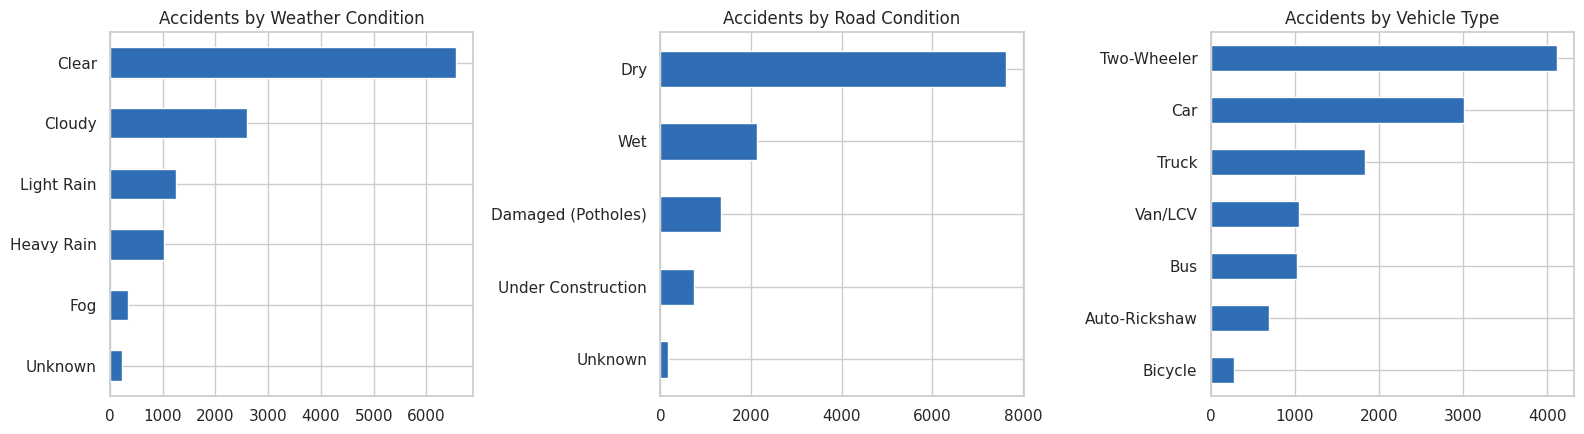

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, col in zip(ax, ["Weather_Condition", "Road_Condition", "Vehicle_Type"]):
    df[col].value_counts().plot(kind="barh", ax=a, color="#2F6DB5", title=f"Accidents by {col.replace('_',' ')}")
    a.invert_yaxis(); a.set_ylabel("")
plt.tight_layout(); plt.show()

### 3.4 Severity - the key question
Counts only tell us where accidents are *frequent*. To find where they are *dangerous*, compare the **severity mix** inside each group.
A helper turns any column into "% Minor / Serious / Fatal".

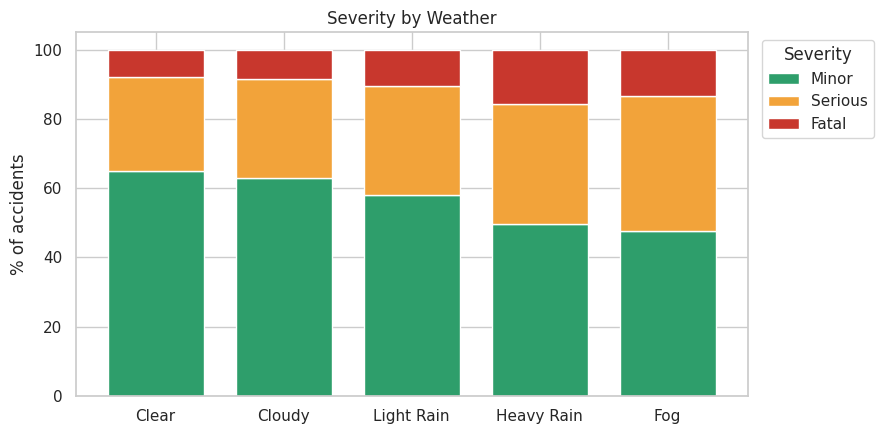

Accident_Severity,Minor,Serious,Fatal
Weather_Condition,,,
Clear,64.9,27.2,7.9
Cloudy,62.9,28.4,8.6
Light Rain,58.1,31.3,10.6
Heavy Rain,49.8,34.5,15.7
Fog,47.6,39.0,13.4


In [10]:
def severity_mix(col, order=None, exclude=("Unknown",)):
    d = df[~df[col].isin(exclude)]
    t = pd.crosstab(d[col], d["Accident_Severity"], normalize="index")[SEV] * 100
    return t.reindex(order) if order is not None else t

def plot_mix(col, title, order=None, rot=0):
    t = severity_mix(col, order)
    ax = t.plot(kind="bar", stacked=True, figsize=(9, 4.5), color=[SEV_COL[s] for s in SEV], rot=rot, width=0.75)
    ax.set_ylabel("% of accidents"); ax.set_xlabel(""); ax.set_title(title)
    ax.legend(title="Severity", bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()
    return t.round(1)

plot_mix("Weather_Condition", "Severity by Weather", ["Clear","Cloudy","Light Rain","Heavy Rain","Fog"])

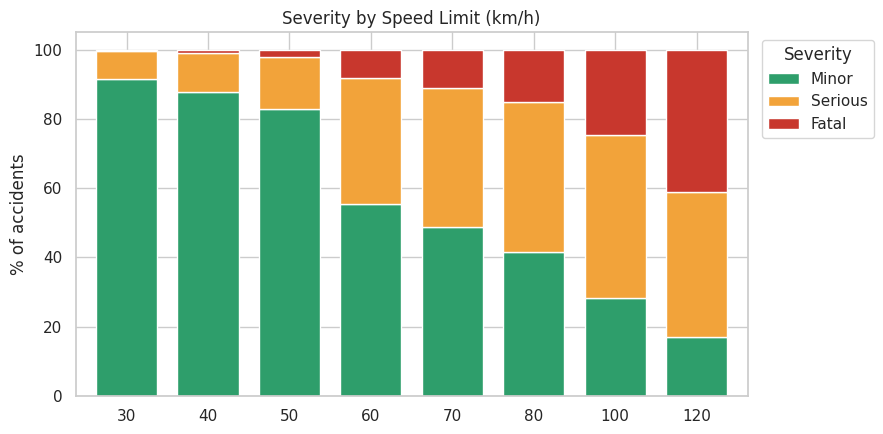

Accident_Severity,Minor,Serious,Fatal
Speed_Limit,,,
30,91.6,8.1,0.3
40,87.9,11.2,1.0
50,82.8,15.1,2.0
60,55.5,36.2,8.3
70,48.7,40.4,10.9
80,41.4,43.4,15.2
100,28.3,47.0,24.7
120,16.9,42.1,41.1


In [11]:
plot_mix("Speed_Limit", "Severity by Speed Limit (km/h)")

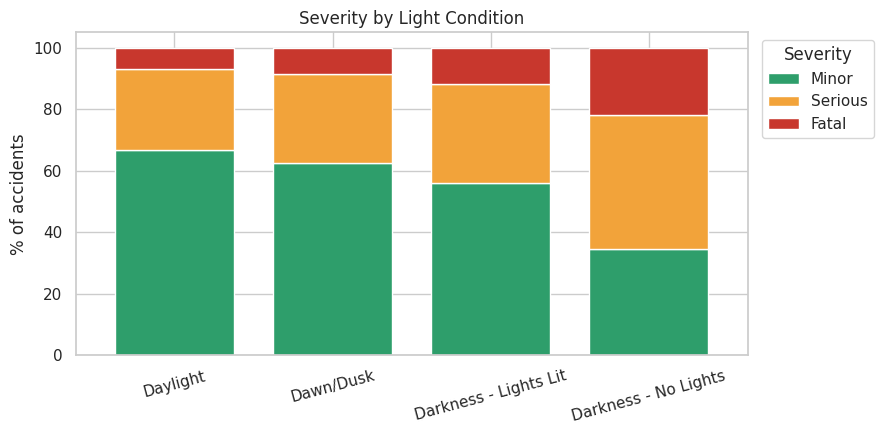

Accident_Severity,Minor,Serious,Fatal
Light_Condition,,,
Daylight,66.7,26.2,7.1
Dawn/Dusk,62.5,29.0,8.5
Darkness - Lights Lit,56.0,32.3,11.7
Darkness - No Lights,34.7,43.3,22.0


In [12]:
plot_mix("Light_Condition", "Severity by Light Condition", ["Daylight","Dawn/Dusk","Darkness - Lights Lit","Darkness - No Lights"], rot=15)

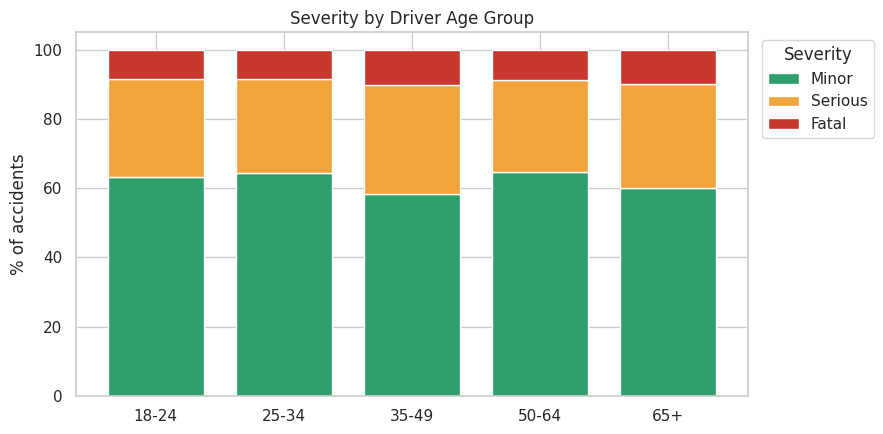

Accident_Severity,Minor,Serious,Fatal
Age_Group,,,
18-24,63.1,28.4,8.4
25-34,64.2,27.2,8.5
35-49,58.4,31.5,10.1
50-64,64.6,26.5,8.9
65+,60.1,30.0,9.9


In [13]:
plot_mix("Age_Group", "Severity by Driver Age Group", ["18-24","25-34","35-49","50-64","65+"])

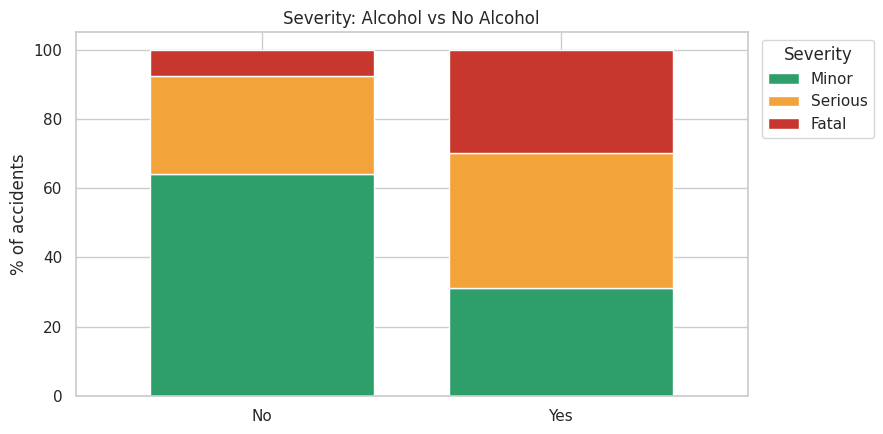

Accident_Severity,Minor,Serious,Fatal
Alcohol_Involved,,,
No,64.2,28.2,7.6
Yes,31.0,39.2,29.7


In [14]:
plot_mix("Alcohol_Involved", "Severity: Alcohol vs No Alcohol")

### 3.5 Locations - which spots are the most dangerous?

In [15]:
loc = (df.groupby(["Location","City"])
         .agg(accidents=("Accident_ID","count"), fatalities=("Number_of_Fatalities","sum"),
              fatal_pct=("Accident_Severity", lambda s: round((s=="Fatal").mean()*100, 1)))
         .query("accidents >= 100").reset_index())
print("Top 10 by NUMBER of accidents");      display(loc.sort_values("accidents", ascending=False).head(10))
print("Top 10 by % of accidents that are FATAL"); display(loc.sort_values("fatal_pct", ascending=False).head(10))

Top 10 by NUMBER of accidents


,Location,City,accidents,fatalities,fatal_pct
24,NH44 Singhu Border,Delhi,420,87,13.8
22,Mathura Road Badarpur,Delhi,374,65,11.2
47,Western Express Highway,Mumbai,369,63,11.9
48,Yamuna Expressway Entry,Delhi,363,145,28.9
44,Tumkur Road NH48,Bengaluru,361,50,9.4
40,Silk Board Junction,Bengaluru,358,14,2.8
41,Sion-Panvel Road,Mumbai,349,50,9.2
35,Ring Road Ashram,Delhi,339,14,2.1
8,ECR Muttukadu,Chennai,328,56,8.8
31,Outer Ring Road Rohini,Delhi,322,1,0.3


Top 10 by % of accidents that are FATAL


,Location,City,accidents,fatalities,fatal_pct
23,Mumbai-Pune Expressway Khandala,Pune,290,154,33.8
48,Yamuna Expressway Entry,Delhi,363,145,28.9
27,Nehru Outer Ring Exit 12,Hyderabad,251,95,28.3
11,Electronic City Elevated,Bengaluru,285,87,22.1
10,Eastern Freeway,Mumbai,307,90,19.9
38,Sardar Patel Ring Road,Ahmedabad,186,64,19.9
29,Outer Ring Road Gachibowli,Hyderabad,241,66,18.3
0,Ajmer Road Sirsi,Jaipur,204,47,15.2
37,Salem-Kochi Highway Madukkarai,Coimbatore,153,28,15.0
7,Delhi Bypass Chomu,Jaipur,189,38,14.3


> **Interview tip:** the two tables above rarely agree. The busiest locations are not the deadliest ones. That is why the dashboard shows *both* volume and fatality rate.

### 3.6 Weekend vs weekday (fair comparison = accidents PER DAY)

In [16]:
wk = df.groupby("Day_Type").agg(accidents=("Accident_ID","count"), days=("Date","nunique"),
        fatal_pct=("Accident_Severity", lambda s: round((s=="Fatal").mean()*100,1)))
wk["accidents_per_day"] = (wk["accidents"] / wk["days"]).round(2)
wk

,accidents,days,fatal_pct,accidents_per_day
Day_Type,,,,
Weekday,8337,1302,8.8,6.40
Weekend,3663,521,9.9,7.03


## 4. Insights & recommendations
Generated by `python/exploratory_analysis.py` - every number is calculated from the data (see `docs/key_insights.md`).

In [17]:
from IPython.display import Markdown
f = ROOT / "docs" / "key_insights.md"
Markdown(f.read_text(encoding="utf-8")) if f.exists() else print("Run: python python/exploratory_analysis.py")

# Key Insights & Recommendations

> Every number below is calculated from `data/cleaned/cleaned_accidents.csv` by `python/exploratory_analysis.py`.

**Definitions:** *Severe* = Serious or Fatal accident. *Fatal %* = share of accidents classified Fatal. *Fatality rate* = fatalities per 100 casualties.

## 0. Overview

- **12,000** accidents, **19,839** casualties, **1,634** fatalities (8.2 deaths per 100 casualties; 1.65 casualties per accident).
- Period: 2019-01-01 to 2023-12-31. Busiest year: **2023** (2,756); quietest: **2020** (1,810).
- Severity mix: Minor 61.9%, Serious 28.9%, Fatal 9.2%.

## 1. When do accidents happen?

- **DATA FINDING:** Peak hours are 18:00 (965), 19:00 (925), 17:00 (760). Busiest day: **Saturday** (1,930); quietest: Tuesday (1,574). Busiest month: **October** (1,144).
- **DATA FINDING:** Late-night accidents (12-4 AM) are fewer (742 vs 4,045 in the 4-8 PM peak) but deadlier: 15.6% fatal vs 6.9% at midday.
- **RECOMMENDATION:** Concentrate traffic police and ambulance coverage between 17:00 and 20:00 (highest volume); add separate drunk-driving and speed checks at night, because fewer accidents there still end more often in death.

## 2. Weather

- **DATA FINDING:** Share of severe accidents by weather: Fog 52.4% (fatal 13.4%); Heavy Rain 50.2% (fatal 15.7%); Light Rain 41.9% (fatal 10.6%); Cloudy 37.1% (fatal 8.6%); Clear 35.1% (fatal 7.9%).
- **DATA FINDING:** **Fog** is the most severe condition: 52.4% severe vs 35.1% in clear weather.
- **RECOMMENDATION:** Trigger weather-based alerts (SMS / variable-message signs) for fog and heavy rain, with temporary speed reductions and fog lights on the affected corridors.

## 3. Road condition

- **DATA FINDING:** Severe-accident share by road condition: Wet 45.2%; Damaged (Potholes) 44.2%; Under Construction 39.8%; Dry 35.0%.
- **DATA FINDING:** Compared with dry roads (35.0% severe), wet roads are +10.2 points and damaged roads +9.2 points.
- **RECOMMENDATION:** Resurface pothole-damaged stretches, improve drainage and anti-skid surfacing where roads are often wet, and add warning signs / barriers around construction zones.

## 4. Vehicle types

- **DATA FINDING:** Most frequent: **Two-Wheeler** (4,111 accidents, 34.3%), then Car (25.0%) and Truck (15.3%).
- **DATA FINDING:** Highest fatal share: **Truck** (14.6%), then Bus (12.6%).
- **RECOMMENDATION:** Run helmet / rider-safety campaigns and enforcement aimed at two-wheeler users; add speed limiters and driver-fatigue rules for truck operators.

## 5. Locations

- **DATA FINDING:** Most accidents: NH44 Singhu Border (420), Mathura Road Badarpur (374), Western Express Highway (369).
- **DATA FINDING:** Highest fatal share: Mumbai-Pune Expressway Khandala - Pune (33.8% fatal), Yamuna Expressway Entry - Delhi (28.9% fatal), Nehru Outer Ring Exit 12 - Hyderabad (28.3% fatal).
- **DATA FINDING:** City with most accidents: **Delhi** (1,818); most fatalities: **Delhi** (312).
- **RECOMMENDATION:** Install speed cameras, better lighting and emergency response points at Mumbai-Pune Expressway Khandala and Yamuna Expressway Entry first, because the same number of accidents there costs more lives.

## 6. Alcohol

- **DATA FINDING:** Alcohol was involved in **6.5%** of accidents with a known alcohol status.
- **DATA FINDING:** 29.7% of alcohol-related accidents were fatal vs 7.6% of the others (**3.9x** higher).
- **DATA FINDING:** Alcohol share is 17.2% between 9 PM-4 AM vs 4.3% during the rest of the day.
- **RECOMMENDATION:** Run breathalyser checkpoints at night and on weekends at the highest-risk locations, and fund a public awareness campaign on drink-driving.

## 7. Weekend vs weekday

- **DATA FINDING:** Weekend days average 7.0 accidents per day vs 6.4 on weekdays. Fatal share: weekend 9.9% vs weekday 8.8%. Alcohol share: weekend 8.8% vs weekday 5.5%.
- **RECOMMENDATION:** Schedule extra patrols and trauma-centre staffing on the busiest days (Saturday and Friday) and on weekend nights, rather than spreading resources evenly across the week.

## 8. Speed, lighting and driver age

- **DATA FINDING (speed):** Fatal share by speed limit: 30 km/h 0.3%, 40 km/h 1.0%, 50 km/h 2.0%, 60 km/h 8.3%, 70 km/h 10.9%, 80 km/h 15.2%, 100 km/h 24.7%, 120 km/h 41.1%. Caution: speed limit is linked to road type (high limits are on expressways/highways), so this shows the *environment's* risk, not only driver speed.
- **DATA FINDING (lighting):** Fatal share by light condition: Darkness - Lights Lit 11.7%, Darkness - No Lights 22.0%, Dawn/Dusk 8.5%, Daylight 7.1%.
- **DATA FINDING (age):** Fatal share by driver age group: 18-24 8.4%, 25-34 8.5%, 35-49 10.1%, 50-64 8.9%, 65+ 9.9%.
- **RECOMMENDATION (speed):** Enforce limits with average-speed cameras on the highest-limit corridors; add rumble strips and median barriers on expressways.
- **RECOMMENDATION (lighting):** Fix street lighting on unlit stretches - **Darkness - No Lights** has the highest fatal share (22.0%).
- **DATA FINDING (age):** Fatal share differs by only 1.7 points between age groups, so age alone is NOT a strong risk factor here; road and environment factors matter more.

## 9. Risk categories

- **DATA FINDING:** Low 61.9%, Medium 17.9%, High 15.9%, Critical 4.3% of accidents (rule-based `Risk_Category`; see data_cleaning.py).
- **DATA FINDING:** 13 mass-casualty accidents (10+ casualties) = 0.11% of accidents but 6.9% of all fatalities; Trucks are the most common vehicle in these events.
- **RECOMMENDATION:** Pre-plan multi-ambulance dispatch rules for heavy-vehicle crashes on highways (they generate the mass-casualty events).


## 5. Next steps
1. Load `data/cleaned/cleaned_accidents.csv` into MySQL (`sql/accident_analysis.sql` or `python/load_to_mysql.py`).
2. Run the 29 SQL queries.
3. Build the Power BI dashboard following `powerbi/dashboard_documentation.md`.